# Experiment 6: A simple neural network (NumPy only)
2-4-1 sigmoid network trained on XOR by backpropagation, for several learning rates.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
HIDDEN, EPOCHS, SEED = 4, 20000, 1
LRS = (0.05, 0.5, 2.0, 10.0)
CONVERGED_MSE = 1e-3       # criterion: final MSE below this AND all four outputs on the correct side of 0.5

def sigmoid(z):
    return 1/(1 + np.exp(-z))

## Why one linear unit is not enough: best single sigmoid unit on XOR

In [2]:
w, b = np.random.default_rng(SEED).normal(0, 1, 2), 0.0
for _ in range(20000):
    o = sigmoid(X @ w + b)
    d = (o - y.ravel())*o*(1 - o)
    w -= 0.5*X.T @ d; b -= 0.5*d.sum()
single = sigmoid(X @ w + b)
print("single unit outputs:", single.round(3), " MSE =", round(float(np.mean((single - y.ravel())**2)), 4))

single unit outputs: [0.5 0.5 0.5 0.5]  MSE = 0.25


## Two-layer network: forward, backward, update

In [3]:
def train_xor(lr, epochs=EPOCHS, seed=SEED, hidden=HIDDEN):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))
    loss = []
    for _ in range(epochs):
        h = sigmoid(X @ W1 + b1)                  # forward
        o = sigmoid(h @ W2 + b2)
        loss.append(float(np.mean((o - y)**2)))
        do = (o - y)*o*(1 - o)                    # output delta  (sigmoid' = o(1-o))
        dh = (do @ W2.T)*h*(1 - h)                # hidden delta  (chain rule)
        W2 -= lr*(h.T @ do); b2 -= lr*do.sum(0, keepdims=True)
        W1 -= lr*(X.T @ dh); b1 -= lr*dh.sum(0, keepdims=True)
    return (W1, b1, W2, b2), np.array(loss)

def predict(params, Xin):
    W1, b1, W2, b2 = params
    return sigmoid(sigmoid(Xin @ W1 + b1) @ W2 + b2)

In [4]:
R = {"shape": f"2-{HIDDEN}-1", "activation": "sigmoid (hidden and output)", "seed": SEED, "epochs": EPOCHS,
     "loss": "mean squared error", "criterion_mse": CONVERGED_MSE,
     "single_unit_outputs": single.round(3).tolist(), "runs": []}
results = {}
for lr in LRS:
    params, loss = train_xor(lr)
    pred = predict(params, X).ravel()
    correct = bool(np.all((pred > 0.5) == (y.ravel() > 0.5)))
    below = np.where(loss < CONVERGED_MSE)[0]
    run = dict(lr=lr, final_mse=float(loss[-1]), all_correct=correct,
               converged=bool(loss[-1] < CONVERGED_MSE and correct),
               epoch_to_criterion=int(below[0]) if below.size else None,
               predictions=pred.round(3).tolist())
    results[lr] = (params, loss); R["runs"].append(run); print(run)

best = min(R["runs"], key=lambda r: r["final_mse"])
R["best_lr"] = best["lr"]

{'lr': 0.05, 'final_mse': 0.0023148689882716935, 'all_correct': True, 'converged': False, 'epoch_to_criterion': None, 'predictions': [0.039, 0.953, 0.954, 0.058]}


{'lr': 0.5, 'final_mse': 0.00011144618732742144, 'all_correct': True, 'converged': True, 'epoch_to_criterion': 3374, 'predictions': [0.008, 0.989, 0.991, 0.013]}


{'lr': 2.0, 'final_mse': 2.455286480396732e-05, 'all_correct': True, 'converged': True, 'epoch_to_criterion': 844, 'predictions': [0.004, 0.995, 0.996, 0.006]}


{'lr': 10.0, 'final_mse': 5.80714908805519e-06, 'all_correct': True, 'converged': True, 'epoch_to_criterion': 193, 'predictions': [0.002, 0.998, 0.998, 0.003]}


## Figures: loss curves and decision boundary of the best run

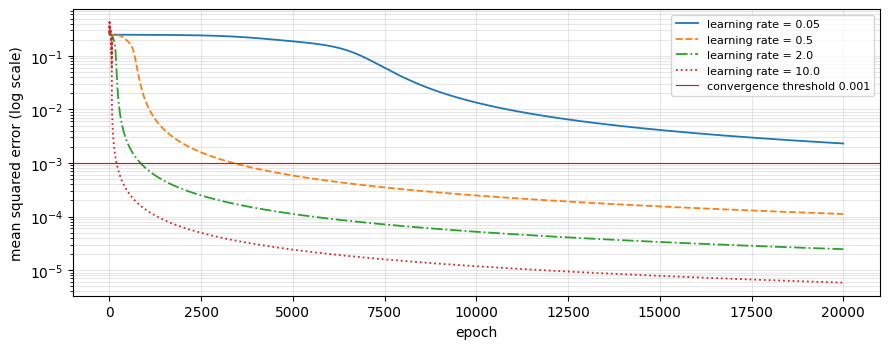

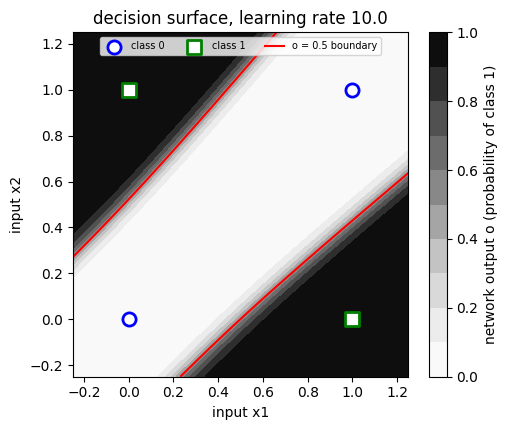

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for lr, st in zip(LRS, ("-", "--", "-.", ":")):
    ax.semilogy(results[lr][1], st, lw=1.3, label=f"learning rate = {lr}")
ax.axhline(CONVERGED_MSE, color="r", lw=0.8, label=f"convergence threshold {CONVERGED_MSE:g}")
ax.set(xlabel="epoch", ylabel="mean squared error (log scale)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); fig.savefig("figs/fig6_1_loss.png", dpi=150); plt.show()

params = results[best["lr"]][0]
gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300), np.linspace(-0.25, 1.25, 300))
Z = predict(params, np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cf = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap="Greys")
ax.contour(gx, gy, Z, levels=[0.5], colors="r", linewidths=1.5)
fig.colorbar(cf, label="network output o (probability of class 1)")
ax.scatter(X[y.ravel() == 0, 0], X[y.ravel() == 0, 1], s=90, marker="o", c="w", edgecolors="b", lw=2, label="class 0")
ax.scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], s=90, marker="s", c="w", edgecolors="g", lw=2, label="class 1")
ax.plot([], [], "r", label="o = 0.5 boundary")
ax.set(xlabel="input x1", ylabel="input x2", title=f"decision surface, learning rate {best['lr']}")
ax.legend(fontsize=7, loc="upper center", ncol=3)
fig.tight_layout(); fig.savefig("figs/fig6_2_boundary.png", dpi=150); plt.show()

In [6]:
json.dump(R, open("results.json", "w"), indent=1)